# 1. IMPORT LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib


# 2. LOAD DATASET

In [2]:

file_path = "restaurant_revenue_uncleaned_2000_rows.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

Dataset loaded successfully!
Shape: (2000, 20)

First 5 rows:
  Restaurant_ID           City  Cuisine_Type  Seating_Capacity  \
0       RES0001          Kochi  North Indian             236.0   
1       RES0002      Hyderabad       Chinese             236.0   
2       RES0003  Visakhapatnam       Mexican              83.0   
3       RES0004          Delhi        Bakery             206.0   
4       RES0005          Kochi           NaN             186.0   

   Average_Meal_Price  Daily_Customers  Staff_Count  Restaurant_Age  \
0               151.0            144.0          7.0             1.0   
1              1566.0            233.0         26.0             9.0   
2               298.0            419.0         29.0             3.0   
3              1683.0            263.0         15.0            12.0   
4              1193.0            205.0         58.0            25.0   

   Online_Rating Delivery_Service Parking_Available  Marketing_Budget  \
0            3.2              Yes        

# 3. UNDERSTANDING THE DATA

In [3]:

print(df.info())


print(df.describe())


print(df.isnull().sum())

print("Number of duplicates:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Restaurant_ID          2000 non-null   object 
 1   City                   1996 non-null   object 
 2   Cuisine_Type           1996 non-null   object 
 3   Seating_Capacity       1994 non-null   float64
 4   Average_Meal_Price     1997 non-null   float64
 5   Daily_Customers        1997 non-null   float64
 6   Staff_Count            1995 non-null   float64
 7   Restaurant_Age         1997 non-null   float64
 8   Online_Rating          1993 non-null   float64
 9   Delivery_Service       1995 non-null   object 
 10  Parking_Available      1998 non-null   object 
 11  Marketing_Budget       1996 non-null   float64
 12  Weekend_Customers      1992 non-null   float64
 13  Operating_Hours        1994 non-null   float64
 14  Festival_Discount      1998 non-null   object 
 15  Cust

# 4. REMOVE DUPLICATES

In [4]:

df = df.drop_duplicates()

print("\nShape after removing duplicates:", df.shape)



Shape after removing duplicates: (1960, 20)


# 5. REMOVE UNNECESSARY ID COLUMN

In [5]:
if "Restaurant_ID" in df.columns:
    df = df.drop("Restaurant_ID", axis=1)

print("\nColumns after removing ID:")
print(df.columns.tolist())



Columns after removing ID:
['City', 'Cuisine_Type', 'Seating_Capacity', 'Average_Meal_Price', 'Daily_Customers', 'Staff_Count', 'Restaurant_Age', 'Online_Rating', 'Delivery_Service', 'Parking_Available', 'Marketing_Budget', 'Weekend_Customers', 'Operating_Hours', 'Festival_Discount', 'Customer_Satisfaction', 'Nearby_Competitors', 'Monthly_Expenses', 'Employee_Experience', 'Monthly_Revenue']


# 6. DEFINE TARGET VARIABLE

In [6]:

target = "Monthly_Revenue"

X = df.drop(target, axis=1)

y = df[target]

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(target)



Features:
['City', 'Cuisine_Type', 'Seating_Capacity', 'Average_Meal_Price', 'Daily_Customers', 'Staff_Count', 'Restaurant_Age', 'Online_Rating', 'Delivery_Service', 'Parking_Available', 'Marketing_Budget', 'Weekend_Customers', 'Operating_Hours', 'Festival_Discount', 'Customer_Satisfaction', 'Nearby_Competitors', 'Monthly_Expenses', 'Employee_Experience']

Target:
Monthly_Revenue


# 7. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES

In [7]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['Seating_Capacity', 'Average_Meal_Price', 'Daily_Customers', 'Staff_Count', 'Restaurant_Age', 'Online_Rating', 'Marketing_Budget', 'Weekend_Customers', 'Operating_Hours', 'Customer_Satisfaction', 'Nearby_Competitors', 'Monthly_Expenses', 'Employee_Experience']

Categorical Features:
['City', 'Cuisine_Type', 'Delivery_Service', 'Parking_Available', 'Festival_Discount']


# 8. TRAIN-TEST SPLIT

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (1568, 18)
Testing data: (392, 18)


# 9 Identify numerical and categorical columns

In [9]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()

print("\nNumerical Columns:")
print(num_cols)

print("\nCategorical Columns:")
print(cat_cols)



Numerical Columns:
['Seating_Capacity', 'Average_Meal_Price', 'Daily_Customers', 'Staff_Count', 'Restaurant_Age', 'Online_Rating', 'Marketing_Budget', 'Weekend_Customers', 'Operating_Hours', 'Customer_Satisfaction', 'Nearby_Competitors', 'Monthly_Expenses', 'Employee_Experience', 'Monthly_Revenue']

Categorical Columns:
['City', 'Cuisine_Type', 'Delivery_Service', 'Parking_Available', 'Festival_Discount']


#  DATA BEFORE TRANSFORMATION

In [10]:

print("DATA BEFORE TRANSFORMATION")

print("\nNumerical Data BEFORE:")
print(df[num_cols].head(10))

print("\nCategorical Data BEFORE:")
print(df[cat_cols].head(10))


DATA BEFORE TRANSFORMATION

Numerical Data BEFORE:
   Seating_Capacity  Average_Meal_Price  Daily_Customers  Staff_Count  \
0             236.0               151.0            144.0          7.0   
1             236.0              1566.0            233.0         26.0   
2              83.0               298.0            419.0         29.0   
3             206.0              1683.0            263.0         15.0   
4             186.0              1193.0            205.0         58.0   
5             254.0               235.0            304.0         14.0   
6              76.0              1938.0            468.0         14.0   
7             194.0              1183.0            509.0         12.0   
8             211.0              1139.0            212.0         53.0   
9             292.0               590.0            344.0         54.0   

   Restaurant_Age  Online_Rating  Marketing_Budget  Weekend_Customers  \
0             1.0            3.2          199393.0              288.0   

# CREATE NUMERICAL TRANSFORMER

In [11]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])



# CREATE CATEGORICAL TRANSFORMER

In [12]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# TRANSFORM NUMERICAL DATA

In [13]:

print("NUMERICAL DATA AFTER TRANSFORMATION")


numeric_data = numeric_transformer.fit_transform(df[num_cols])

numeric_after = pd.DataFrame(
    numeric_data,
    columns=num_cols,
    index=df.index
)

print(numeric_after.head(10))



NUMERICAL DATA AFTER TRANSFORMATION
   Seating_Capacity  Average_Meal_Price  Daily_Customers  Staff_Count  \
0             236.0               151.0            144.0          7.0   
1             236.0              1566.0            233.0         26.0   
2              83.0               298.0            419.0         29.0   
3             206.0              1683.0            263.0         15.0   
4             186.0              1193.0            205.0         58.0   
5             254.0               235.0            304.0         14.0   
6              76.0              1938.0            468.0         14.0   
7             194.0              1183.0            509.0         12.0   
8             211.0              1139.0            212.0         53.0   
9             292.0               590.0            344.0         54.0   

   Restaurant_Age  Online_Rating  Marketing_Budget  Weekend_Customers  \
0             1.0            3.2          199393.0              288.0   
1             

# TRANSFORM CATEGORICAL DATA

In [14]:

print("CATEGORICAL DATA AFTER TRANSFORMATION")


categorical_data = categorical_transformer.fit_transform(df[cat_cols])

# Get encoded column names
encoded_columns = (
    categorical_transformer
    .named_steps["encoder"]
    .get_feature_names_out(cat_cols)
)

categorical_after = pd.DataFrame(
    categorical_data.toarray(),
    columns=encoded_columns,
    index=df.index
)

print(categorical_after.head(10))

CATEGORICAL DATA AFTER TRANSFORMATION
   City_Bengaluru  City_Chennai  City_Delhi  City_Hyderabad  City_Jaipur  \
0             0.0           0.0         0.0             0.0          0.0   
1             0.0           0.0         0.0             1.0          0.0   
2             0.0           0.0         0.0             0.0          0.0   
3             0.0           0.0         1.0             0.0          0.0   
4             0.0           0.0         0.0             0.0          0.0   
5             0.0           0.0         0.0             0.0          0.0   
6             1.0           0.0         0.0             0.0          0.0   
7             0.0           0.0         0.0             0.0          0.0   
8             0.0           0.0         0.0             0.0          0.0   
9             0.0           0.0         0.0             0.0          0.0   

   City_Kochi  City_Mumbai  City_Pune  City_Vijayawada  City_Visakhapatnam  \
0         1.0          0.0        0.0          

# DISPLAY SHAPES

In [15]:

print("DATA SHAPES AFTER TRANSFORMATION")


print("Original Numerical Shape :", df[num_cols].shape)
print("Transformed Numerical Shape :", numeric_after.shape)

print("Original Categorical Shape :", df[cat_cols].shape)
print("Transformed Categorical Shape :", categorical_after.shape)


print("\n✔ Transformation completed successfully.")


DATA SHAPES AFTER TRANSFORMATION
Original Numerical Shape : (1960, 14)
Transformed Numerical Shape : (1960, 14)
Original Categorical Shape : (1960, 5)
Transformed Categorical Shape : (1960, 26)

✔ Transformation completed successfully.


# 10. CREATE PREPROCESSOR

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)


# 11. CREATE RANDOM FOREST MODEL

In [17]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# 12. CREATE COMPLETE ML PIPELINE

In [18]:
pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            model
        )
    ]
)

# 13. TRAIN MODEL

In [19]:

print("\nTraining Random Forest model...")

pipeline.fit(
    X_train,
    y_train
)

print("Model training completed!")



Training Random Forest model...
Model training completed!


# 14. MAKE PREDICTIONS

In [20]:

y_pred = pipeline.predict(X_test)

# 15. MODEL EVALUATION

In [21]:
mae = mean_absolute_error(
    y_test,
    y_pred
)

mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    y_pred
)


print("\n================ MODEL EVALUATION ================")

print("Mean Absolute Error (MAE):", mae)

print("Mean Squared Error (MSE):", mse)

print("Root Mean Squared Error (RMSE):", rmse)

print("R² Score:", r2)


================ MODEL EVALUATION ================
Mean Absolute Error (MAE): 433472.9058200103
Mean Squared Error (MSE): 324376789669.005
Root Mean Squared Error (RMSE): 569540.8586475644
R² Score: 0.9942981235202861


# 16. ACTUAL VS PREDICTED VALUES

In [22]:
results = pd.DataFrame({
    "Actual Revenue": y_test.values,
    "Predicted Revenue": y_pred
})

print("\n================ ACTUAL VS PREDICTED ================")

print(results.head(20))




================ ACTUAL VS PREDICTED ================
    Actual Revenue  Predicted Revenue
0        2108365.5       2.324512e+06
1        3401206.0       4.128653e+06
2       12391887.5       1.102487e+07
3        2606627.0       2.639280e+06
4        3318707.5       3.300767e+06
5       11938907.5       1.110960e+07
6       11546059.5       1.044596e+07
7       12906283.0       1.370106e+07
8        9300635.0       9.712726e+06
9        5462972.5       4.788653e+06
10       1125320.5       1.282172e+06
11        217618.5       5.309026e+05
12       6866681.0       7.436121e+06
13        659991.5       1.015383e+06
14       7876655.5       9.041573e+06
15       6477224.0       6.670293e+06
16      15002083.5       1.376639e+07
17       1422129.0       1.458423e+06
18      25196386.0       2.523850e+07
19       4796071.0       4.095020e+06


# 17. PLOT ACTUAL VS PREDICTED

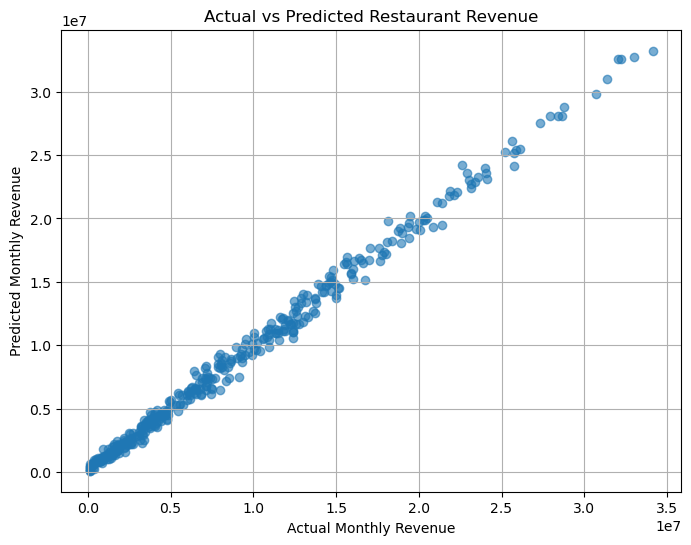

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.xlabel("Actual Monthly Revenue")

plt.ylabel("Predicted Monthly Revenue")

plt.title(
    "Actual vs Predicted Restaurant Revenue"
)

plt.grid(True)

plt.show()


# 18. FEATURE IMPORTANCE

In [24]:
# Get feature names after preprocessing

feature_names = pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = pipeline.named_steps[
    "model"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\n================ FEATURE IMPORTANCE ================")

print(
    feature_importance.head(20)
)



================ FEATURE IMPORTANCE ================
                        Feature  Importance
2          num__Daily_Customers    0.497396
1       num__Average_Meal_Price    0.494183
11        num__Monthly_Expenses    0.002818
0         num__Seating_Capacity    0.000666
7        num__Weekend_Customers    0.000549
6         num__Marketing_Budget    0.000474
10      num__Nearby_Competitors    0.000470
4           num__Restaurant_Age    0.000445
30    cat__Cuisine_Type_Mexican    0.000396
9    num__Customer_Satisfaction    0.000382
8          num__Operating_Hours    0.000374
3              num__Staff_Count    0.000372
5            num__Online_Rating    0.000329
12     num__Employee_Experience    0.000322
17             cat__City_Jaipur    0.000128
28  cat__Cuisine_Type_Fast Food    0.000074
15              cat__City_Delhi    0.000057
36   cat__Parking_Available_Yes    0.000050
20               cat__City_Pune    0.000048
35    cat__Parking_Available_No    0.000041


# 19. FEATURE IMPORTANCE VISUALIZATION

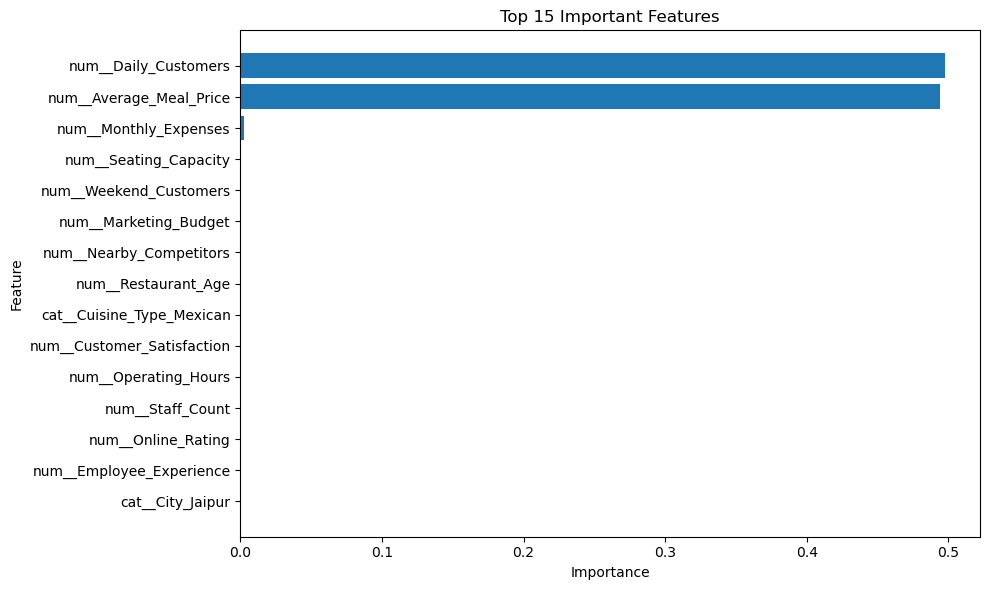

In [25]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")

plt.ylabel("Feature")

plt.title(
    "Top 15 Important Features"
)

plt.tight_layout()

plt.show()


# 20. PREDICT REVENUE FOR A NEW RESTAURANT

In [26]:
new_restaurant = pd.DataFrame({

    "City": ["Hyderabad"],

    "Cuisine_Type": ["Chinese"],

    "Seating_Capacity": [150],

    "Average_Meal_Price": [500],

    "Daily_Customers": [250],

    "Staff_Count": [20],

    "Restaurant_Age": [5],

    "Online_Rating": [4.3],

    "Delivery_Service": ["Yes"],

    "Parking_Available": ["Yes"],

    "Marketing_Budget": [100000],

    "Weekend_Customers": [500],

    "Operating_Hours": [12],

    "Festival_Discount": ["Yes"],

    "Customer_Satisfaction": [8.5],

    "Nearby_Competitors": [5],

    "Monthly_Expenses": [1000000],

    "Employee_Experience": [5]
})


predicted_revenue = pipeline.predict(
    new_restaurant
)


print("\n================ NEW RESTAURANT PREDICTION ================")

print(
    "Predicted Monthly Revenue:",
    predicted_revenue[0]
)


================ NEW RESTAURANT PREDICTION ================
Predicted Monthly Revenue: 3117867.8561137263


# 21. FORMAT REVENUE

In [27]:

print(
    f"Predicted Monthly Revenue: ₹{predicted_revenue[0]:,.2f}"
)


Predicted Monthly Revenue: ₹3,117,867.86


# 22. SAVE MODEL

In [28]:
model_filename = "restaurant_revenue_model.pkl"

joblib.dump(
    pipeline,
    model_filename
)

print(
    f"\nModel saved successfully as: {model_filename}"
)



Model saved successfully as: restaurant_revenue_model.pkl


# 23. LOAD SAVED MODEL

In [29]:
loaded_model = joblib.load(
    model_filename
)

print("Saved model loaded successfully!")


Saved model loaded successfully!


# 24. TEST LOADED MODEL

In [30]:
test_prediction = loaded_model.predict(
    new_restaurant
)

print(
    f"Prediction from loaded model: ₹{test_prediction[0]:,.2f}"
)

Prediction from loaded model: ₹3,117,867.86
